# 27 · Burned area: maps, SQL and a moving season

**Time:** 45 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** query historical fire values; distinguish extensive totals from area-normalized quantities; animate a season.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=27_seasfire_maps_sql.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Use the same values in Python and the SQL lab

The lab carries **2018–2021** to keep its 184 × 16 × 16 cube below the browser's cell budget.
The NPZ retains all 21 years for time-series analysis. Python uses SQLite; the linked lab follows
the zarr-sql-views approach with Zarrita, Arrow, DuckDB-WASM and deck.gl.
Both operate on the same burned-area values, with explicit dates and units.

In [2]:
from seasfire import load_seasfire, raster
d=load_seasfire('ghana')
meta,fire=load_cube('seasfire_ghana')
np.testing.assert_array_equal(fire,d['gwis_ba'][d['dates']>=np.datetime64('2018-01-01')])
con=sql_connection(meta,fire)
rows=list(con.execute('SELECT t, COUNT(value), SUM(value) FROM cells GROUP BY t ORDER BY t'))
totals=np.array([r[2] for r in rows])
np.testing.assert_allclose(totals,np.sum(fire,axis=(1,2),dtype=float))
peak=int(np.argmax(totals))
print('Largest period total in this window:',meta['times'][peak],round(totals[peak]),'ha')
print('Contributing cells:',rows[peak][1])

Largest period total in this window: 2019-11-17 1639939 ha
Contributing cells: 256


## 2. Compare a total with a normalized map

Burned area is extensive: add hectares over disjoint cells. ERA5 precipitation is a depth, so summing
millimeters over cells is not a regional rainfall statistic. Normalize fire area with SeasFire's `area`
in m²: `100 × burned_ha × 10,000 / cell_area`. This uses the **whole grid cell**, not its land-only area.
It is a product-derived area ratio; repeated burning and product errors can complicate an annual ratio.
Do not clip unexpected values silently.

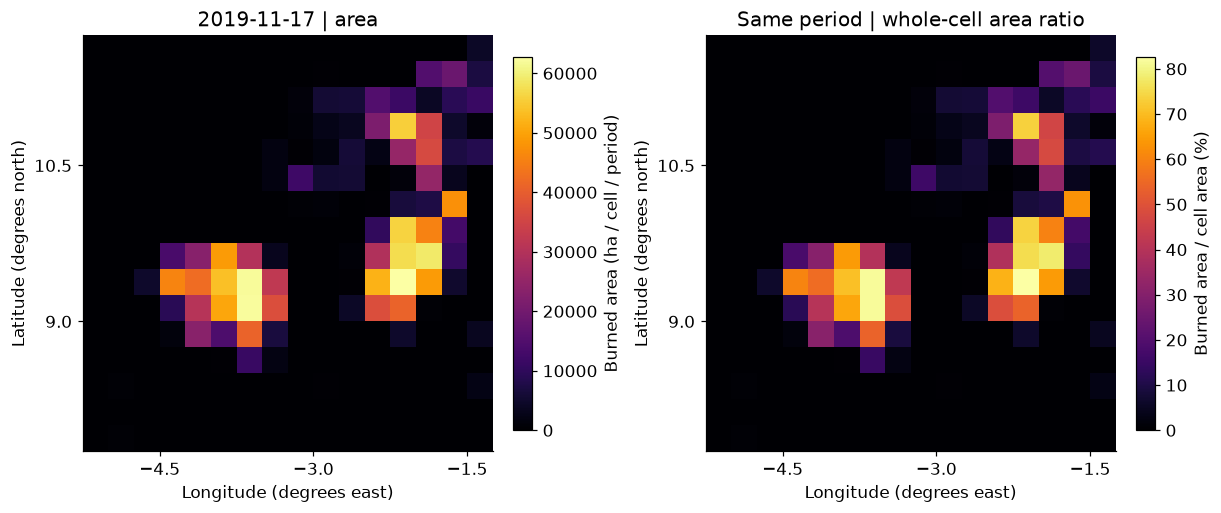

85 cells exceed 500 ha in that period; not a count of fires.


In [3]:
percent=100*fire[peak]*10000/d['area']
fig,axes=plt.subplots(1,2,figsize=(11,5),layout='constrained')
a=raster(axes[0],d,fire[peak],meta['times'][peak]+' | area')
b=raster(axes[1],d,percent,'Same period | whole-cell area ratio')
fig.colorbar(a,ax=axes[0],label='Burned area (ha / cell / period)',shrink=.7)
fig.colorbar(b,ax=axes[1],label='Burned area / cell area (%)',shrink=.7)
plt.show()
threshold=500
count=con.execute('SELECT COUNT(*) FROM cells WHERE t=? AND value>?',(peak,threshold)).fetchone()[0]
assert count==int(np.sum(fire[peak]>threshold))
print(count,'cells exceed',threshold,'ha in that period; not a count of fires.')

## 3. Watch a year without changing the color scale

The animation uses all 46 bins in 2019, a fixed color range, and labels each interval duration.
Playback advances by bin, so short year-end intervals take the same screen time as eight-day bins.
GWIS assigns burned areas using ignition dates; the animation is not an active-fire video.

In [4]:
from matplotlib.animation import FuncAnimation
keep=d['year']==2019
frames=d['gwis_ba'][keep]; dates=d['dates'][keep]; durations=d['duration_days'][keep]
fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
image=raster(ax,d,frames[0],'',vmax=float(np.nanmax(frames)))
fig.colorbar(image,ax=ax,label='Burned area (ha / cell / period)')
def update(i):
    image.set_array(frames[i].ravel())
    ax.set_title(f"GWIS / SeasFire | {dates[i]} | {durations[i]} days")
    return image,
animation=FuncAnimation(fig,update,frames=len(frames),interval=180)
display(HTML(animation.to_jshtml(default_mode='loop')))
plt.close(fig)

## 4. Move from map to space–time cube

Open the lab, filter `value > 500 AND t < 46`, then change between map, columns, cube and scene.
Columns encode burned-area magnitude. In the time cube the vertical axis is the **period index**.
Neither display represents terrain height. Exported points retain source, license and temporal support.

In [5]:
lab('seasfire_ghana','cube')

## Try it yourself

Repeat with Zambia. Compare the 2019 peaks using dates, totals and contributing area. Explain what a country comparison would require.

## Check your reasoning

These equal-sized angular windows cross administrative boundaries and differ in area and ecology. Country totals require boundaries, support-aware aggregation and coverage checks.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [SeasFire Cube v0.4, Alonso et al. (2024)](https://doi.org/10.5281/zenodo.13834057), CC-BY-4.0. Spatial subsets and browser repackaging by this course; no spatial resampling.
- [Karasante, Alonso, Prapas, Ahuja, Carvalhais & Papoutsis (2025), SeasFire cube — a multivariate dataset for global wildfire modeling](https://doi.org/10.1038/s41597-025-04546-3), Scientific Data 12, 368.
- [ESA Open Science Catalog / EarthCODE](https://opensciencedata.esa.int/products/seasfire-cube/item), public SeasFire v0.4 mirror. Inputs used: GWIS burned area, ECMWF/Copernicus ERA5, NASA MODIS MOD13C1 v6 NDVI, and SeasFire derived VPD/cell area.
- [Exact source objects, SHA256 checksums, extraction windows and transformations](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/seasfire-provenance.json).
- [Söchting, Scheuermann, Montero & Mahecha (2025), Interactive Earth system data cube visualization in Jupyter notebooks](https://doi.org/10.1080/20964471.2025.2471646), Big Earth Data, 1–15. [LexCube 2.0.1](https://github.com/msoechting/lexcube), Maximilian Söchting and contributors, GPL-3.0-or-later.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 27_seasfire_maps_sql')

LESSON COMPLETE: 27_seasfire_maps_sql
